# P2.01 — Spatial autocorrelation of prices and affordability

**Questions:** RQ4.4 (are neighbouring municipalities alike, i.e. is there room for spatial spillovers?),
RQ4.3 (are urban centres different from their surroundings?), RQ4.6 (where are the clusters).

Method (`src/pthousing/analysis/spatial.py`):
* **Weights:** queen contiguity, row-standardised, links never cross the sea (an island municipality with no land
  neighbour is linked to its two nearest in the same archipelago). The check uses the 6 nearest centroids.
* **Global Moran's I** with a permutation p-value (999 permutations); **LISA** and **Gi\*** for where.

Spatial autocorrelation is a *pattern*, not a mechanism: neighbours resemble each other because they share
income, coast, labour markets and policy as much as because prices spill over. The last section asks how much of
the pattern remains once regional averages are removed.

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import spatial
from pthousing.data import build_panel, interim
from pthousing.viz import charts, maps, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
geo = interim.read("caop_municipalities")  # metres, unsimplified: contiguity needs exact borders
geometry = maps.municipality_geometry()
names = geo.set_index("muni_code")[["muni_name", "district", "nuts3_name_2024"]]

w_queen = spatial.build_weights(geo, "queen")
w_knn = spatial.build_weights(geo, "knn", k=6)
print(
    f"queen: mean {w_queen.mean_neighbors:.1f} neighbours, min {w_queen.min_neighbors}, "
    f"max {w_queen.max_neighbors}; knn6: mean {w_knn.mean_neighbors:.1f}"
)

queen: mean 5.0 neighbours, min 1, max 10; knn6: mean 6.0


## Levels: how alike are neighbours, and has it changed?

series  income  price    pti
year                        
2016     0.611  0.649  0.630
2017     0.611  0.658  0.645
2018     0.613  0.658  0.661
2019     0.616  0.694  0.700
2020     0.604  0.709  0.702
2021     0.603  0.712  0.714
2022     0.597  0.728  0.734
2023     0.577  0.737  0.748
2024     0.560  0.749  0.756


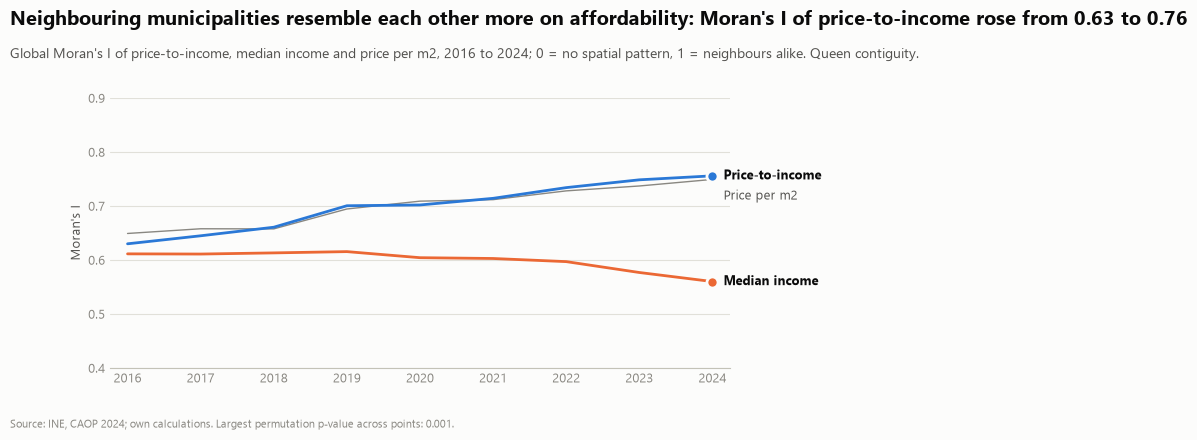

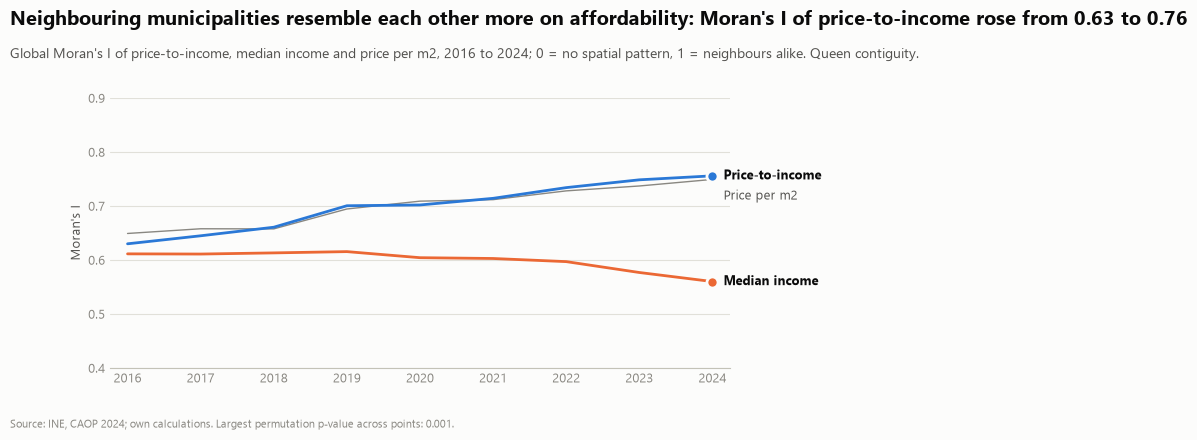

In [2]:
YEARS = list(range(2016, 2025))
series = {"pti": "pti_years", "income": "income_median_eur_real", "price": "price_sqm_eur_real"}
trend = pd.concat(
    [
        spatial.moran_by_year(panel, col, w_queen, YEARS).assign(series=key)
        for key, col in series.items()
    ],
    ignore_index=True,
)
fig = charts.moran_trends(trend, "Queen contiguity.")
style.save_fig(fig, "p2", "moran_levels_by_year")
style.save_table(
    trend[["series", "year", "I", "z_sim", "p_sim", "n"]], "p2", "moran_levels_by_year"
)
print(trend.pivot(index="year", columns="series", values="I").round(3).to_string())
fig

## Changes 2016 to 2024: is the *deterioration* clustered?

In [3]:
wide = panel.set_index(["muni_code", "year"])
changes = {
    "Change in price-to-income, 2016 to 2024 (years)": (
        wide["pti_years"].unstack()[2024] - wide["pti_years"].unstack()[2016]
    ),
    "Real price per m2 growth, 2016 to 2025 (log)": np.log(
        wide["price_sqm_eur_real"].unstack()[2025] / wide["price_sqm_eur_real"].unstack()[2016]
    ),
    "Real median income growth, 2016 to 2024 (log)": np.log(
        wide["income_median_eur_real"].unstack()[2024]
        / wide["income_median_eur_real"].unstack()[2016]
    ),
}
rows = []
for label, values in changes.items():
    for wname, w in (("queen", w_queen), ("knn6", w_knn)):
        rows.append({"variable": label, "weights": wname, **spatial.global_moran(values, w)})
robust = pd.DataFrame(rows)
style.save_table(robust, "p2", "moran_changes")
print(robust.round(3).to_string(index=False))

                                       variable weights     I  expected  z_sim  p_sim   n
Change in price-to-income, 2016 to 2024 (years)   queen 0.718    -0.003 18.350  0.001 296
Change in price-to-income, 2016 to 2024 (years)    knn6 0.674    -0.003 21.107  0.001 296
   Real price per m2 growth, 2016 to 2025 (log)   queen 0.448    -0.003 11.414  0.001 302
   Real price per m2 growth, 2016 to 2025 (log)    knn6 0.365    -0.003 11.648  0.001 302
  Real median income growth, 2016 to 2024 (log)   queen 0.532    -0.003 14.119  0.001 297
  Real median income growth, 2016 to 2024 (log)    knn6 0.539    -0.003 17.014  0.001 297


## Is it just regional averages? Clustering within regions
Subtract the mean of each NUTS 3 sub-region and test again. If the pattern were only coast against interior,
little would remain; what remains is clustering *within* regions (a first look, not a spillover test).

In [4]:
pti_change = changes["Change in price-to-income, 2016 to 2024 (years)"]
region = names["nuts3_name_2024"].reindex(pti_change.index)
within = pti_change - pti_change.groupby(region).transform("mean")
within_rows = []
for label, values in (("Raw", pti_change), ("Minus NUTS 3 mean", within)):
    for wname, w in (("queen", w_queen), ("knn6", w_knn)):
        within_rows.append({"series": label, "weights": wname, **spatial.global_moran(values, w)})
within_tbl = pd.DataFrame(within_rows)
style.save_table(within_tbl, "p2", "moran_within_regions")
print(within_tbl.round(3).to_string(index=False))

           series weights     I  expected  z_sim  p_sim   n
              Raw   queen 0.718    -0.003 18.350  0.001 296
              Raw    knn6 0.674    -0.003 21.107  0.001 296
Minus NUTS 3 mean   queen 0.197    -0.003  5.136  0.001 296
Minus NUTS 3 mean    knn6 0.077    -0.003  2.446  0.008 296


## Where: LISA clusters and Gi\* hotspots of the deterioration

{'ns': 201, 'LL': 50, 'HH': 45} | Gi*: {'ns': 201, 'cold': 50, 'hot': 45}
HH vs hot agree for 100% of municipalities
       district  HH  LL  HL  LH  ns
           Faro  13   0   0   0   2
         Lisboa  11   0   0   0   5
        Setúbal   8   0   0   0   5
          Porto   6   2   0   0  10
Ilha da Madeira   3   0   0   0   5
           Beja   1   1   0   0  10
       Santarém   1   0   0   0  20
   Ilha do Pico   1   0   0   0   2


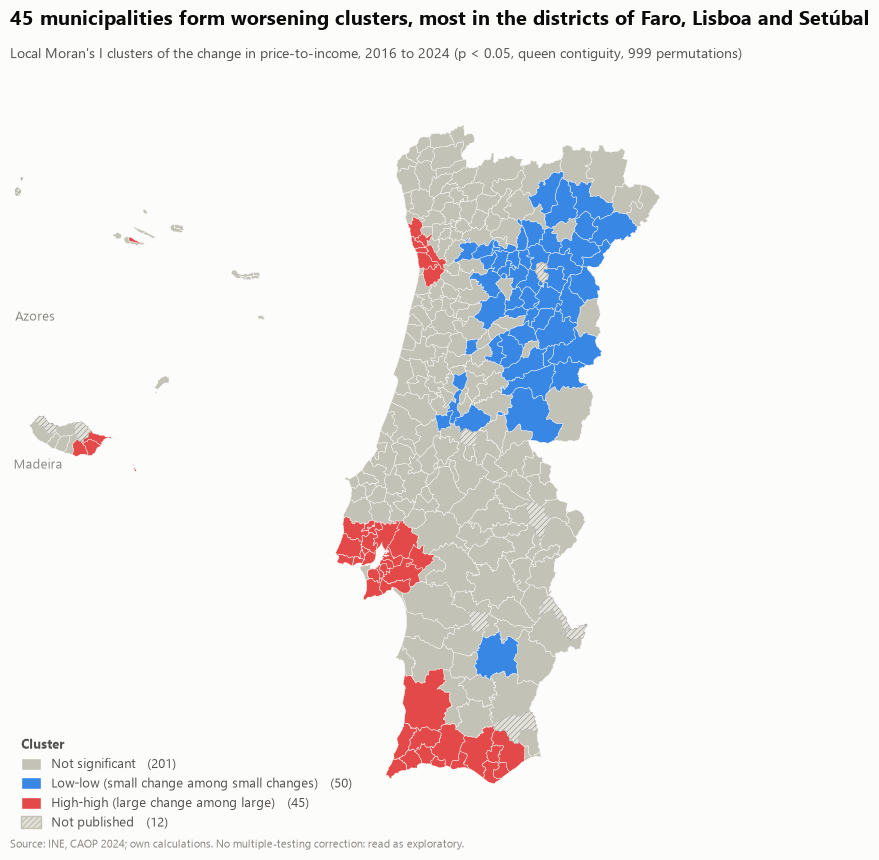

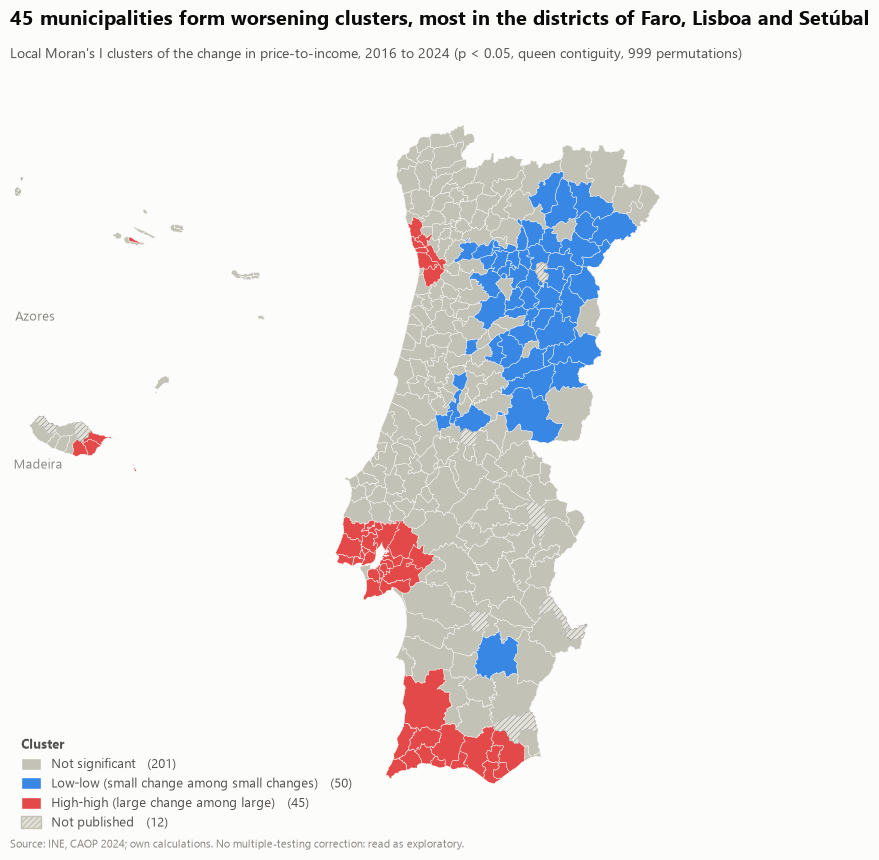

In [5]:
lisa = spatial.local_moran(pti_change, w_queen)
gi = spatial.getis_ord_gistar(pti_change, w_queen)
both = lisa.join(gi, rsuffix="_gi").join(names)
counts = lisa["cluster"].value_counts()
print(counts.to_dict(), "| Gi*:", gi["hotspot"].value_counts().to_dict())
agree = ((both["cluster"] == "HH") == (both["hotspot"] == "hot")).mean()
print(f"HH vs hot agree for {agree:.0%} of municipalities")

by_district = (
    both.assign(n=1)
    .pivot_table(index="district", columns="cluster", values="n", aggfunc="sum", fill_value=0)
    .reindex(columns=["HH", "LL", "HL", "LH", "ns"], fill_value=0)
    .sort_values("HH", ascending=False)
    .reset_index()
)
style.save_table(by_district, "p2", "lisa_clusters_by_district")
print(by_district.head(8).to_string(index=False))
top = by_district[by_district["HH"] > 0].head(3)["district"].tolist()
title = (
    f"{counts.get('HH', 0)} municipalities form worsening clusters, most in the districts of "
    f"{', '.join(top[:-1])} and {top[-1]}"
)

code = {"ns": 0, "LL": 1, "HH": 2}
coded = lisa["cluster"].map(code)
fig = maps.choropleth(
    coded,
    geometry,
    [0.5, 1.5],
    [style.BASELINE, style.BLUE_RAMP[400], style.RED_REFERENCE],
    title,
    "Local Moran's I clusters of the change in price-to-income, 2016 to 2024 (p < 0.05, queen contiguity, 999 permutations)",
    "Source: INE, CAOP 2024; own calculations. No multiple-testing correction: read as exploratory.",
    "Cluster",
    labels=[
        "Not significant",
        "Low-low (small change among small changes)",
        "High-high (large change among large)",
    ],
)
style.save_fig(fig, "p2", "lisa_pti_change_map")
fig

In [6]:
focus = both.loc[both["muni_name"].isin(["Lisboa", "Porto", "Cascais", "Faro", "Braga", "Coimbra"])]
print(focus[["muni_name", "quadrant", "p_sim", "cluster", "hotspot"]].round(3).to_string())
outliers = both[both["quadrant"].isin(["HL", "LH"]) & (both["cluster"] != "ns")]
print(f"significant spatial outliers (HL/LH): {len(outliers)}")

          muni_name quadrant  p_sim cluster hotspot
muni_code                                          
0303          Braga       HH  0.403      ns      ns
0603        Coimbra       LL  0.159      ns      ns
0805           Faro       HH  0.007      HH     hot
1105        Cascais       HH  0.007      HH     hot
1106         Lisboa       HH  0.003      HH     hot
1312          Porto       HH  0.003      HH     hot
significant spatial outliers (HL/LH): 0


## Findings

1. **Neighbours resemble each other, and more each year (RQ4.4).** Moran's I of price-to-income rose from 0.63
   in 2016 to 0.76 in 2024 and that of the real price per m² from 0.65 to 0.75, while that of income fell from
   0.61 to 0.56. Every value is significant (permutation p < 0.01) and the 6-nearest-neighbour weights give the
   same picture. The geography of prices is concentrating faster than that of incomes.
2. **The deterioration itself is clustered.** Moran's I of the change in price-to-income 2016 to 2024 is 0.72
   (0.67 with k-nearest weights), higher than for price growth (0.45) or income growth (0.53) alone.
3. **Most of that is regional, not local.** After subtracting each NUTS 3 sub-region's mean, Moran's I falls to
   0.20 with queen weights and 0.08 with 6 nearest neighbours (both still significant, p < 0.01). So the pattern is
   mainly coast against interior and metropolitan area against rest; a small, weights-dependent part is
   clustering *within* regions. This is evidence that spillovers are *possible*, not that they exist: a spatial
   lag or Durbin model on the panel (p2_03) is needed to test them.
4. **Clusters.** 45 municipalities are high-high and 50 low-low (p < 0.05, no multiple-testing correction). The
   high-high clusters are concentrated in the districts of Faro (13), Lisboa (11), Setúbal (8) and Porto (6);
   Lisboa, Porto, Cascais and Faro are inside them. The low-low clusters are the interior (Viseu, Guarda,
   Bragança, Castelo Branco).
5. **No urban islands (RQ4.3).** No municipality is a significant high-low or low-high outlier: the large
   centres did not pull away from their surroundings in the change in price-to-income; they moved with them.
   Gi\* flags exactly the same municipalities as the LISA clusters, which is a consistency check on the
   implementation more than independent confirmation (the two statistics are closely related).

**Caveats.** Municipal prices start in 2016, so these are 8-year changes. Contiguity weights treat very
unequal municipalities alike; the k-nearest variant shows how sensitive the *within-region* result is.